<a href="https://colab.research.google.com/github/LiaIssakov/Portfolio_2025/blob/main/dot_product_and_projection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Properties of the dot-product



Before, the methods were focused on computing the Euclidean distance between two points. Now we focus more on the dot product, which (later) will allow us to devise methods using projections. Today, we try to understand/recall basic properties.

The dot product will also be the **basis for essentially all of deep learning...**

In [ ]:
import numpy as np
from numpy.linalg import norm

import matplotlib.pyplot as plt

# disregard, technicalities
from ipywidgets import *
import ipywidgets as widgets

# Some useful functions and a constant

In [ ]:
def vec2d(x,y): return np.array((x,y)) # returns a 2D vector as an np.array

# normalizes a vector (returns a unit vector pointing in the same direction)
def normalized(v): return v / norm(v)

ORIGIN = vec2d(0, 0) # we will use it to refer to the origin of R^2

# Just play with the interactive plot below!

In [ ]:
'''I wrote two functions for you: draw_point() and draw_arrow()
There is no need to look at the implementations!
'''

def draw_point(v, txt = "", color = 'b'):
  '''I just plot a point. No need to look inside.'''
  plt.scatter(*v, c = color)
  plt.axis('equal') # otherwise it looks ugly
  if txt:
    plt.text(*(v + np.array((0.01, 0))), txt, c = 'gray', fontsize = 20)


def draw_arrow(v, t, txt = "", color = 'g', bold = False):
  '''I plot a nice arrow between v,t. No need to look inside, just try me out.'''
  v = np.asarray(v)
  t = np.asarray(t)
  dxy = t-v
  plt.scatter(*v, c = 'k')
  plt.scatter(*(v+dxy), c = 'k', alpha = 0)
  head_width = np.linalg.norm(dxy)/20. * [1,2.5][bold]
  line_width = 1 if not bold else 2
  plt.arrow(*v, *dxy, length_includes_head = True,
            head_width = head_width, linewidth = line_width, color = color)
  if txt:
    plt.text(*(v+dxy/2. + (0.01, 0)), txt, c = 'gray', fontsize = 20)
  plt.axis('equal') # otherwise it looks ugly

In [ ]:
# just technicalities -- play with the interactive plot

sl_len = lambda x : widgets.FloatSlider(value=x,
                                        min = 0, max = 3, step = 0.01)
sl_ang = lambda x : widgets.FloatSlider(value=x,
                                        min = 0, max = 2*np.pi, step = 0.01)

def plot_dot(ang1, len1, ang2, len2):
  # plt.sca(ax)
  plt.cla()
  v = vec2d(np.cos(ang1), np.sin(ang1))*len1
  u = vec2d(np.cos(ang2), np.sin(ang2))*len2
  draw_arrow(ORIGIN, v, color = 'red', txt = 'v')
  draw_arrow(ORIGIN, u, color = 'green', txt = 'u')

  dp = np.round(np.dot(u,v),3)
  plt.title(f'u={np.round(u,3)}\nv={np.round(v,3)}\n<u,v> = {dp} (value of the dot-product)')

  #plt.axis('equal')
  plt.xlim(-3,3)
  plt.show()


#fig = plt.figure(figsize = (8,8))
#ax = plt.gca()

interactive_plot = interactive(plot_dot,
                               ang1 = sl_ang(0.5), len1 = sl_len(2),
                               ang2 = sl_ang(0), len2 = sl_len(1))
interactive_plot.layout.height = '1000px'
interactive_plot.layout.width = '800px'
HBox([interactive_plot])

# The dot product is super useful!

## Today we will try to develop intuitions for three of its properties which make it particularly useful in data-science.

Dot product (or scalar product) is defined is a function which takes two $d$-dimensional vectors and returns a scalar:
$$\begin{align}
\mathbb{R}^d \times \mathbb{R}^d &\rightarrow \mathbb{R}\\
 u,v &\mapsto \sum_{i=0}^{d-1} u_i v_i
\end{align}
$$

We will often denote the dot product between $u$, $v$ as $\langle u,v \rangle$.

In 2D $\langle (a,b),(c,d) \rangle = ac + bd$.

In python we will use np.dot(u,v) where u,v are np.arrays.

TIP: You can also write np.dot(P, v) where $P$ is a bunch of vectors. You'll get all dot products between the rows of P and $v$.

> Important: The dot product between two vectors **gives a single real number** (not a vector, not a matrix, not a tensor, not a string). Just a number.

# Standard interpretations

- $\langle u,v \rangle = cos(\angle(u,v)) \|u\|_2 \|v\|_2$, namely the cosine of the angle between the two vectors (in any dimension!) times the product of their lengths.

> So if $u,v$ are unit vectors, we just get the cosine of the angle between them. Very useful.

> If you want to get the angle itself, you can use arccos (np.arccos)! It returns the result in radians.

- It's often useful to just look at the sign of the dot product -- in this case the lengths of the vectors don't matter. See below.

- Below we discuss another important interpretation!



# Important interpretation: Halfspaces determined by the dot-product



You can use dot product to partition the space. As you will see in a couple of classes, this property is used for example in classifiers (like the SVM classifier), but also to interpret the computation done by a single neuron in basic neural networks.

> Note that we're not just partitioning the data -- this is really a way of partitioning all of the (uncountably) infinitely many point in $\mathbb{R}^d$ (here: $\mathbb{R}^2$).

##Task 1: For a given vector $v$, plot points with positive (in green) and negative (in red) dot product with $v$. How does this divide the space?

EXTRA (for later): Could we do the same if the vector was *anchored* at some point other than the origin (so that we can have more freedom in choosing the subdivision)?

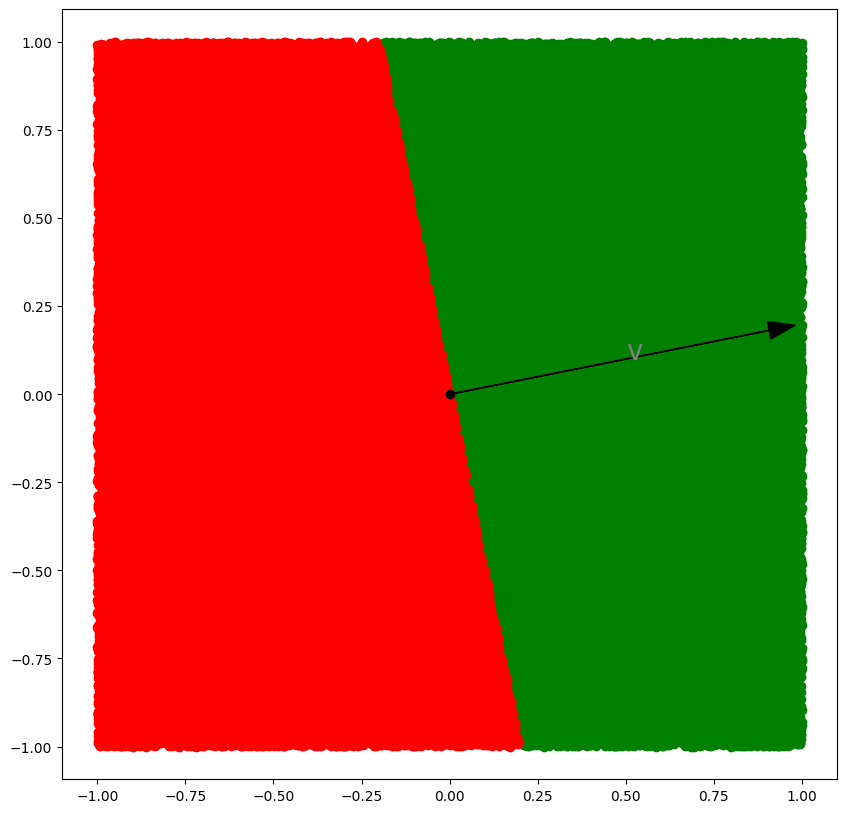

In [ ]:
np.random.seed(1)
plt.figure(figsize = (10,10))

n = 100_000
X = np.random.rand(n,2)*2 - 1

v = normalized(vec2d(0.5,0.1))

# computes the dot product with v for each vector in X!
dot_products = np.dot(X, v)

# we did get n values
assert dot_products.shape[0] == n

# TODO: finish! (basic numpy, using True/False masks, we did it before!)
positive = X # ...
negative = X # ...
zeros = X # ...

plt.scatter(*positive.T, c='green')
plt.scatter(*negative.T, c='red')
plt.scatter(*zeros.T, c='blue')

draw_arrow(ORIGIN, v, txt='v', color='k')

# Aside: Euclidean norm/distance from dot product

In [ ]:
a,b = np.random.rand(2,2)
dist = np.linalg.norm(a-b)
print(dist)
print(np.dot(a-b, a-b)**0.5)

0.6071928103278804
0.6071928103278804


In [ ]:
norm(a)

np.float64(1.0272584614240634)

In [ ]:
np.dot(a,a)**0.5

np.float64(1.0272584614240634)

# A super important interpretation: Dot product as projection length (especially onto a UNIT vector)




We can view the dot product as the **projection length onto a unit vector**.

> More technically we project onto the **span** of a vector $v$, namely all vectors of the form $tv$ for $t \in \mathbb{R}$.

> Do you see for one vector, the span is just a line through the origin?

In the simple case below, taking the dot product of vector $a$ with $b = (1,0)$ simply selects a single (first) component of the vector $a$. If we scale $b$ by the result, we get a vector which is the orthogonal projection of $a$ onto the horozontal axis (see picture).




proj length onto the unit vector is: 0.5


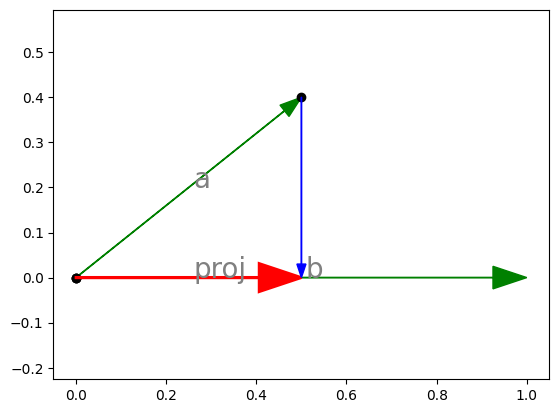

In [ ]:
a = vec2d(.5,.4)
b = vec2d(1,0) # unit vector!

draw_arrow(ORIGIN, a, 'a')
draw_arrow(ORIGIN, b, 'b')

length = np.dot(a, b)

print(f'proj length onto the unit vector is: {length}')

proj = b*length

draw_arrow(ORIGIN, proj, 'proj', color='red', bold=True)
draw_arrow(a, proj, color='blue')

## Task 2. Repeat the construction from point 1, if $b$ is an arbitrary vector?

Construct a **vector** which is the result of projecting $a$ orthogonally on any vector $b$. Visualize it as above.

> Additionally visualize projecting $b$ onto $a$. How is it different? How much can the projection length change?

> Remember that **this vector is not the dot product**! The dot product gives just a number.




As you will see in a couple of weeks, this property is used in methods using projections, including PCA, SVM, random projections...


In [ ]:
a = vec2d(.1,.5)
b = vec2d(0.5,.35)

def project(a, b):
  '''Returns the vector which is the result of projecting
   a onto b, using dot product.
  '''
  # TODO: finish! Try to do this on your own in a few steps.
  # Looking up an existing formula is not that useful.
  return a+b # wrong!

proj = project(a, b)
assert len(proj) == 2

draw_arrow(ORIGIN, a, 'a')
draw_arrow(ORIGIN, b, 'b')

draw_arrow(ORIGIN, proj, 'b', color='red')
draw_arrow(a, proj, '', color='blue')

NameError: name 'vec2d' is not defined

# Optional harder Task 3 (reflection using dot products)
## ... or linear algebra for playing pool


Find the direction such that a laser ray emitted from point $o$ in this direction and reflected from the mirror (see picture) will hit the target. (Assume that the angle of incidence is equal to the angle of reflection.)

> Note that there is a wall so that you cannot hit the target directly.

> And no, the laser will not pierce the wall. It's a very solid wall. You really have to find the good reflection point on the mirror.



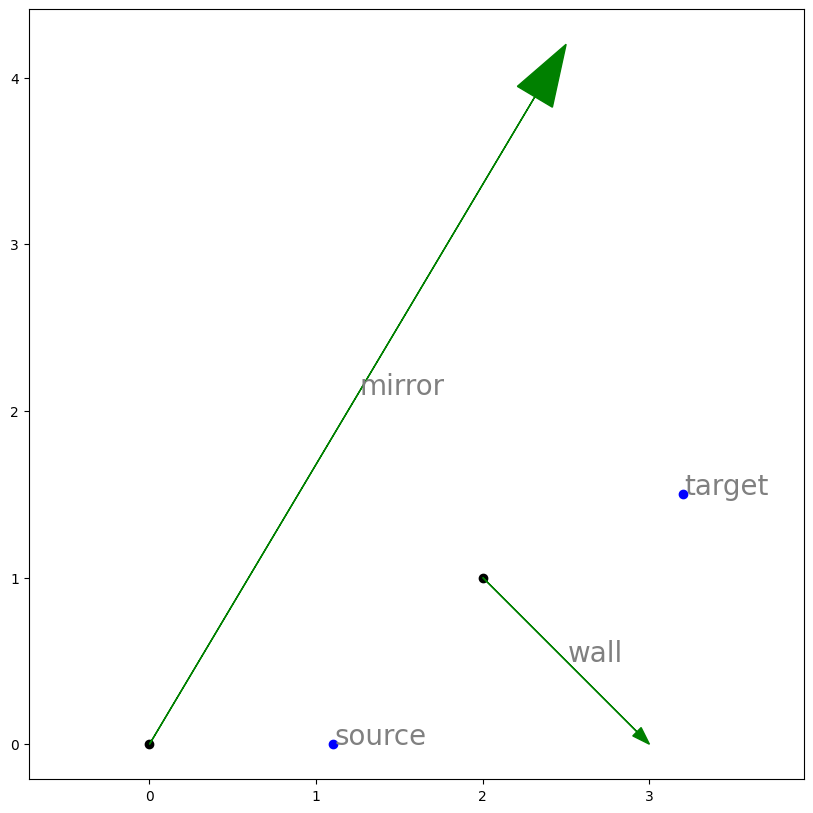

In [ ]:
plt.figure(figsize = (10,10))
mirror = vec2d(2.5,4.2)
o = vec2d(1.1,0)
t = vec2d(3.2,1.5)
draw_arrow(ORIGIN, mirror, 'mirror')
draw_arrow((2,1.), (3,0), 'wall')
draw_point(o, 'source')
draw_point(t, 'target')

# finish up!